# 1. Dataset Loading + Initial Exploration

In [1]:
import pandas as pd
df = pd.read_csv('/kaggle/input/datasets/lyesaitk/house-train/train.csv')

In [2]:
print("=== Shape of the dataset ===")
print(df.shape)

=== Shape of the dataset ===
(1460, 81)


In [3]:
print("\n=== First 5 rows (head) ===")
print(df.head())


=== First 5 rows (head) ===
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  Sale

In [4]:
print("\n=== Dataset Information (info) ===")
df.info()


=== Dataset Information (info) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1

In [5]:
print("\n=== Statistical Summary of Numerical Columns (describe) ===")
print(df.describe())


=== Statistical Summary of Numerical Columns (describe) ===
                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.11

# 2. MISSING VALUES

In [6]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_df = pd.DataFrame({
    'missing_count' : missing ,
    'missing_percentage' : missing_percent
}) 

print("==== TOTAL DATASET COLUMNS ==")
print(len(df))
print(" ==== TOTAL COLUMNS WITH MISSING VALUES ==== ")
print(len(missing_df[missing_df['missing_count'] > 0]))
print(" ==== ALL COLUMNS WITH THEIR MISSING VALUES COUNT ==== ")
print(missing_df[missing_df['missing_count'] > 0])

==== TOTAL DATASET COLUMNS ==
1460
 ==== TOTAL COLUMNS WITH MISSING VALUES ==== 
19
 ==== ALL COLUMNS WITH THEIR MISSING VALUES COUNT ==== 
              missing_count  missing_percentage
PoolQC                 1453           99.520548
MiscFeature            1406           96.301370
Alley                  1369           93.767123
Fence                  1179           80.753425
MasVnrType              872           59.726027
FireplaceQu             690           47.260274
LotFrontage             259           17.739726
GarageQual               81            5.547945
GarageFinish             81            5.547945
GarageType               81            5.547945
GarageYrBlt              81            5.547945
GarageCond               81            5.547945
BsmtFinType2             38            2.602740
BsmtExposure             38            2.602740
BsmtCond                 37            2.534247
BsmtQual                 37            2.534247
BsmtFinType1             37            2.534

# 3. CORRELATION HEATMAP

==== TOP CORRELATED FEATURES ====
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


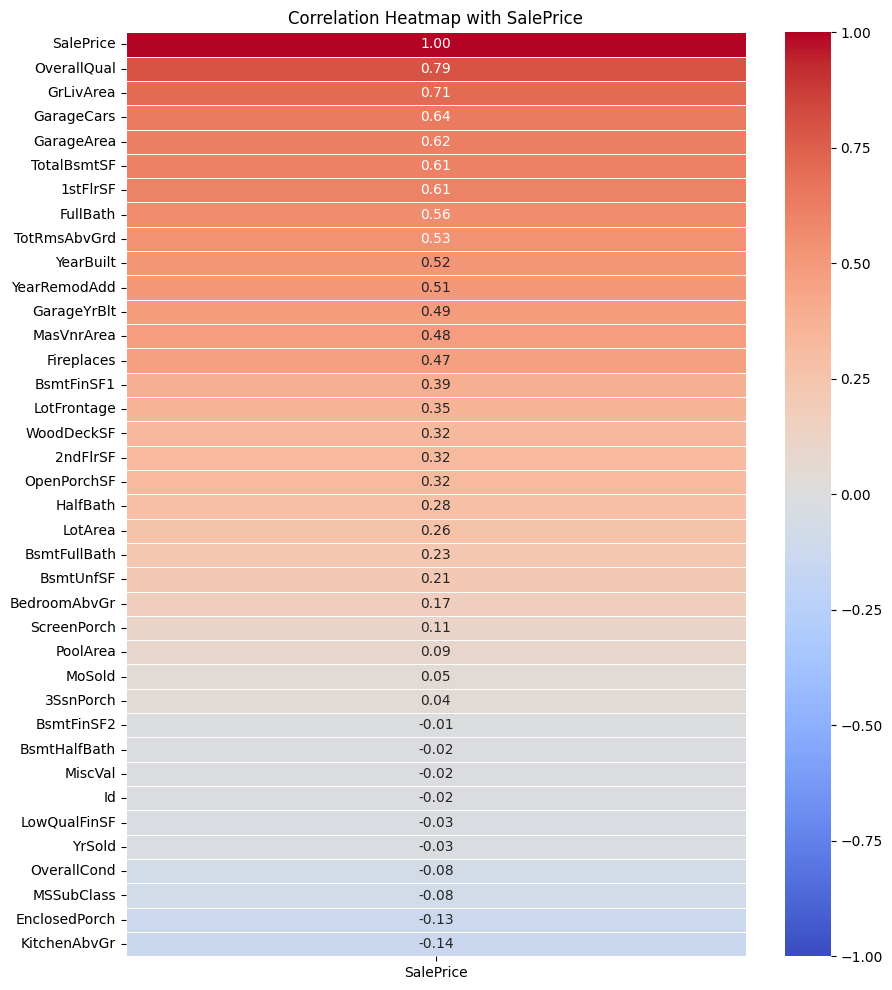

In [7]:
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns

print("==== TOP CORRELATED FEATURES ====")
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix=numeric_df.corr()
top_corr = corr_matrix['SalePrice'].abs().sort_values(ascending=False).head(15)
print(top_corr)

plt.figure(figsize=(10,12))
sns.heatmap(corr_matrix[['SalePrice']].sort_values(by='SalePrice', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt='.2f')
plt.title("Correlation Heatmap with SalePrice")
plt.show()

# 4. VISUALIZE IMPORTANT FEATURES

 ==== MOST IMPORTANT FEATURES ==== 


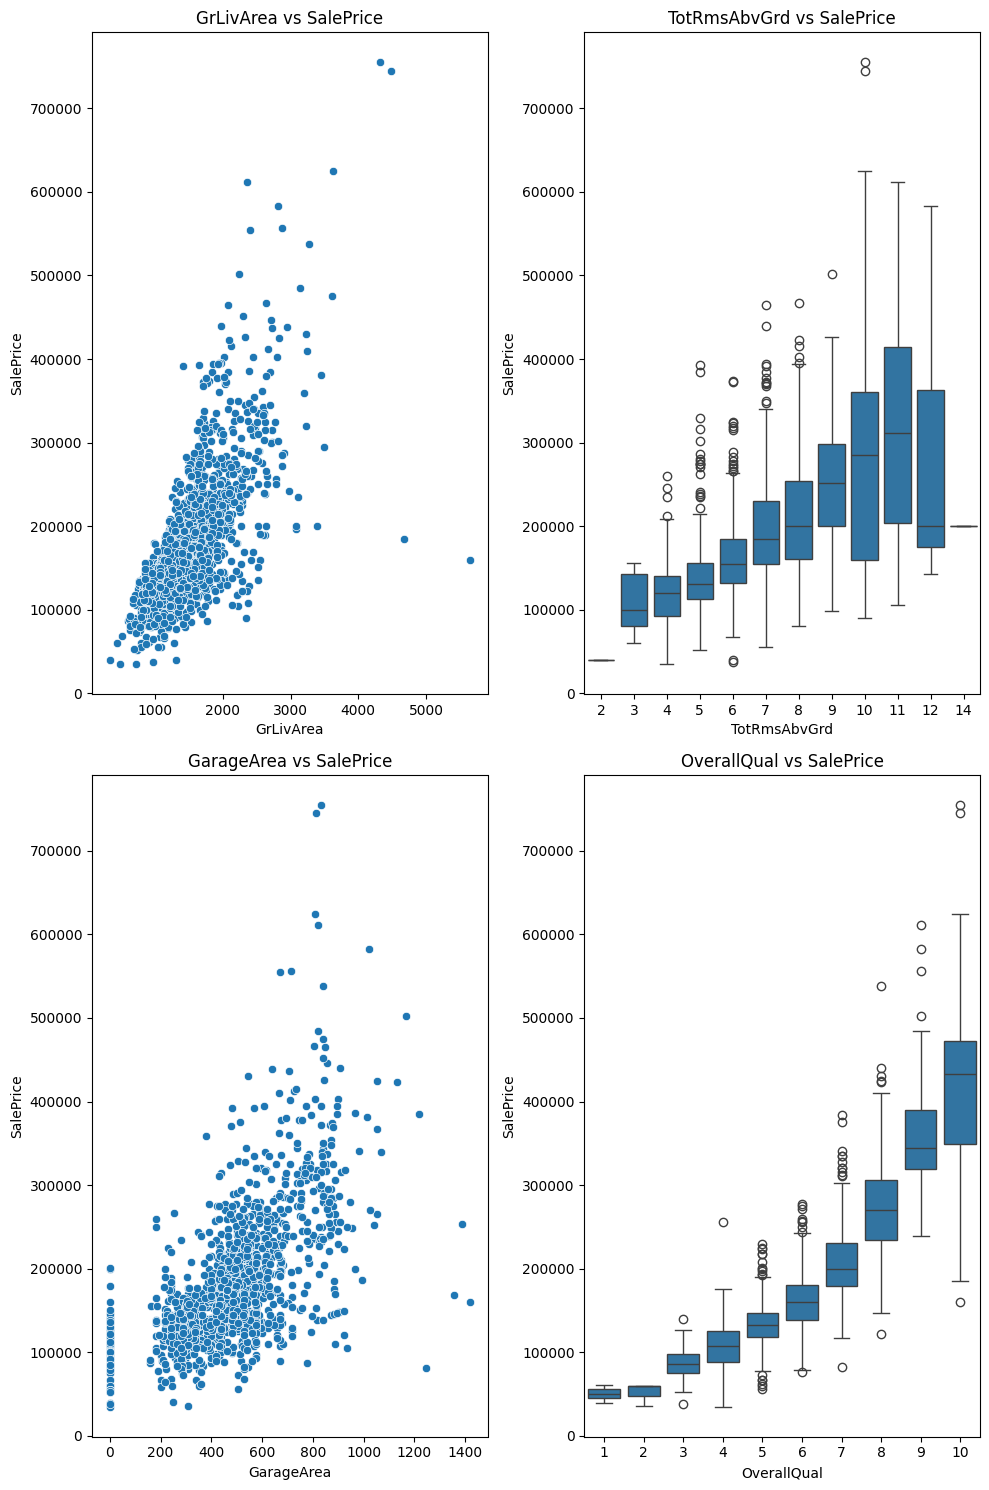

In [8]:
print(" ==== MOST IMPORTANT FEATURES ==== ")
fig ,axes = plt.subplots(2 ,2 ,figsize=(10,15))
sns.scatterplot(x='GrLivArea' ,y='SalePrice' ,data=df ,ax=axes[0,0])
axes[0,0].set_title('GrLivArea vs SalePrice')

sns.boxplot(x='TotRmsAbvGrd' ,y='SalePrice' ,data=df ,ax=axes[0,1])
axes[0,1].set_title('TotRmsAbvGrd vs SalePrice')

sns.scatterplot(x='GarageArea' ,y='SalePrice' ,data=df ,ax=axes[1,0])
axes[1,0].set_title('GarageArea vs SalePrice')

sns.boxplot(x='OverallQual' ,y='SalePrice' ,data=df ,ax=axes[1,1])
axes[1,1].set_title('OverallQual vs SalePrice')

plt.tight_layout()
plt.show()

# 4. HANDLING MISSING VALUES

In [9]:
print("Shape before handling the messing values : ",df.shape)

# 1. Drop High missing values pecentage values cols > 80%
dropped_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence']
dropped_cols = [col for col in dropped_cols if col in df.columns]
df.drop(columns=dropped_cols ,inplace=True)

# 2. Replace values with None in cols with categorical values
none_cols = ['MasVnrType', 'FireplaceQu', 'GarageType', 'GarageFinish', 
             'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 
             'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

for c in none_cols:
    df[c] = df[c].fillna('None')


# 3. Impute numerical columns 
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
df['MasVnrArea'] = df['MasVnrArea'].fillna(df['MasVnrArea'].median()) 

# 4. Impute Electrical 
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print("Shape after handling missing values : ",df.shape)
print("="*10 ," REMAINING MISSING VALUES ","="*10)
remain_miss = df.isnull().sum().sort_values(ascending=False)
print(remain_miss[remain_miss > 0])

print("MISSING VALUES HANDLED !")

Shape before handling the messing values :  (1460, 81)
Shape after handling missing values :  (1460, 77)
==========  REMAINING MISSING VALUES  ==========
Series([], dtype: int64)
MISSING VALUES HANDLED !


# 5. ENCODING CATEGORICAL FEATURES

In [10]:
print("Shape before encoding : ",df.shape)
print()

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Number of categorical columns : {len(categorical_cols)}")
print("="*10 ," ALL CATEGORICAL COLUMNS ","="*10)
print(categorical_cols)
print()

#One-Hot Encoding
df_encoded = pd.get_dummies(df ,columns=categorical_cols ,drop_first=True)
print("New shape after encoding : ",df_encoded.shape)
print()

# Examples
print("First 5 columns from encoded DataFrame")
print(df_encoded.columns[:10].tolist())
print()

print("Categorical features encoded !")

Shape before encoding :  (1460, 77)

Number of categorical columns : 39
==========  ALL CATEGORICAL COLUMNS  ==========
['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']

New shape after encoding :  (1460, 248)

First 5 columns from encoded DataFrame
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1']

Categorical features encoded !


# 7. TRAIN / TEST SPLIT

In [11]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop('SalePrice', axis=1)
y = df_encoded['SalePrice']

# Correct split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

print("=== Train/Test Split ===")
print(f"X_train shape : {X_train.shape}")
print(f"X_test shape  : {X_test.shape}")
print(f"y_train shape : {y_train.shape}")
print(f"y_test shape  : {y_test.shape}")
print(f"Total samples : {len(X_train) + len(X_test)}")

=== Train/Test Split ===
X_train shape : (1168, 247)
X_test shape  : (292, 247)
y_train shape : (1168,)
y_test shape  : (292,)
Total samples : 1460


# 8. TRAIN MODELS

## 8.a. Decision Tree

In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error ,r2_score
import numpy as np

dt_model = DecisionTreeRegressor(
    max_depth = 10,
    random_state=42
)

dt_model.fit(X_train ,y_train)

y_pred_train_dt = dt_model.predict(X_train)
y_pred_test_dt = dt_model.predict(X_test)

print("="*15 ," DT PERFORMANCE ","="*15)
print("Training RMSE = ",np.sqrt(mean_squared_error(y_train ,y_pred_train_dt)))
print("Test RMSE = ",np.sqrt(mean_squared_error(y_test ,y_pred_test_dt)))
print("Training Chi-Square = ",r2_score(y_train ,y_pred_train_dt))
print("Test Chi-Square = ",r2_score(y_test ,y_pred_test_dt))

===============  DT PERFORMANCE  ===============
Training RMSE =  8374.11331778712
Test RMSE =  39296.056684079704
Training Chi-Square =  0.9882429069428301
Test Chi-Square =  0.7986813038705574


## 8.b. Linear Regression

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error ,r2_score
import numpy as np

lr_model = LinearRegression()
lr_model.fit(X_train ,y_train)

y_pred_train_lr = lr_model.predict(X_train)
y_pred_test_lr = lr_model.predict(X_test)

print("="*15 ," LR PERFORMANCE ","="*15)
print("Training RMSE = ",np.sqrt(mean_squared_error(y_train ,y_pred_train_lr)))
print("Test RMSE = ",np.sqrt(mean_squared_error(y_test ,y_pred_test_lr)))
print("Training R² = ",r2_score(y_train ,y_pred_train_lr))
print("Test R² = ",r2_score(y_test ,y_pred_test_lr))

===============  LR PERFORMANCE  ===============
Training RMSE =  19694.662877432533
Test RMSE =  52522.334845968166
Training R² =  0.9349691559029729
Test R² =  0.6403548450016132


## 8.c. Random Forest

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators = 100, #Number of trees
    max_depth = 12, 
    random_state = 42,
    n_jobs = -1 #Uses all CPU cores
)

rf_model.fit(X_train ,y_train)

y_pred_train_rf = rf_model.predict(X_train)
y_pred_test_rf = rf_model.predict(X_test)

print("="*15 ," RF PERFORMANCE ","="*15)
print(f"Training RMSE : {np.sqrt(mean_squared_error(y_train, y_pred_train_rf)):.2f}")
print(f"Test RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred_test_rf)):.2f}")
print(f"Training R²   : {r2_score(y_train, y_pred_train_rf):.4f}")
print(f"Test R²       : {r2_score(y_test, y_pred_test_rf):.4f}")

===============  RF PERFORMANCE  ===============
Training RMSE : 11569.06
Test RMSE     : 28924.31
Training R²   : 0.9776
Test R²       : 0.8909


**Random Forest** is clearly the winner among the three baselines. It has the lowest test error and best generalization. And for that i shall first try some **Hyperparameter tuning**

### 8.c.1. RF Hyperparameter Tuning

In [15]:
from sklearn.model_selection import RandomizedSearchCV

##
param_dist = {
    'n_estimators' : [100 ,200 ,300 ,500],
    'max_depth' : [10 ,15 ,20 ,25 ,None],
    'min_samples_split' : [2 ,5 ,10],
    'min_samples_leaf' : [1 ,2 ,4],
    'max_features' : ['sqrt' ,'log2' ,None]
}

#Base Model
rf = RandomForestRegressor(random_state=42, n_jobs=-1)

#Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter = 20, #number of random combos
    cv = 5,
    scoring = 'neg_root_mean_squared_error',
    verbose = 2,
    n_jobs = -1
)

random_search.fit(X_train ,y_train)

print("\n Best Model found : ")
# Get the best model (not just the parameters)
best_rf = random_search.best_estimator_

print("\nBest Parameters Found:")
print(random_search.best_params_)

# Predictions with the best model
y_pred_train = best_rf.predict(X_train)
y_pred_test = best_rf.predict(X_test)

print("\n=== Tuned Random Forest Performance ===")
print(f"Training RMSE : {np.sqrt(mean_squared_error(y_train, y_pred_train)):.2f}")
print(f"Test RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred_test)):.2f}")
print(f"Training R²   : {r2_score(y_train, y_pred_train):.4f}")
print(f"Test R²       : {r2_score(y_test, y_pred_test):.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

 Best Model found : 

Best Parameters Found:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15}

=== Tuned Random Forest Performance ===
Training RMSE : 13820.05
Test RMSE     : 29584.41
Training R²   : 0.9680
Test R²       : 0.8859


## 8.d. Gradient Boosting and XGBoost 

In [16]:
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#=========
# 1. GB 
#=========
gb_model = GradientBoostingRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 5,
    random_state = 42
)

gb_model.fit(X_train ,y_train)

y_pred_gb = gb_model.predict(X_test)

print("\n=== Gradient Boosting Performance ===")
print("Test RMSE = ",np.sqrt(mean_squared_error(y_test ,y_pred_gb)))
print("Test R² = ",r2_score(y_test ,y_pred_gb))


#==================
# 2. XGB Regressor
#==================

xgb_model = XGBRegressor(
    n_estimators = 300,
    learning_rate = 0.1,
    max_depth = 5,
    random_state = 42,
    eval_metrics = 'rmse'
)

xgb_model.fit(X_train ,y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("\n=== XGBoost Regressor Performance ===")
print("Test RMSE = ",np.sqrt(mean_squared_error(y_test ,y_pred_xgb)))
print("Test R² = ",r2_score(y_test ,y_pred_xgb))


=== Gradient Boosting Performance ===
Test RMSE =  26344.93830030489
Test R² =  0.909514177715605


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:46:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



=== XGBoost Regressor Performance ===
Test RMSE =  26279.900152017322
Test R² =  0.9099603891372681


### 8.d.1. XGBoost Hyperparameter tuning

In [17]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

param_grid = {
    'n_estimators' : [100 ,200 ,300 ,500],
    'learning_rate' : [0.05 ,0.1 ,0.15],
    'max_depth' : [3 ,5 ,7 ,9],
    'subsample' : [0.8 ,0.9 ,1.0],
    'min_child_weight' : [1 ,3 ,5 ,7],
    'colsample_bytree' : [0.8 ,0.9 ,1.0]
}

xgb = XGBRegressor(random_state=42, eval_metric='rmse')

random_search = RandomizedSearchCV(
    estimator = xgb ,
    param_distributions = param_grid,
    n_iter = 30,
    cv = 5,
    scoring = 'neg_root_mean_squared_error',
    verbose = 2,
    random_state = 42,
    n_jobs = -1
)

print("Starting Hyperparameter Tuning .....")
random_search.fit(X_train ,y_train)

print("\n Best Model found : ")
# Get the best model (not just the parameters)
best_xgb = random_search.best_estimator_

print("\nBest Parameters Found:")
print(random_search.best_params_)

y_pred_test = best_xgb.predict(X_test)

print("\n=== Tuned XGBoost Performance ===")
print("Test RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_test)))
print("Test R²   :", r2_score(y_test, y_pred_test))

Starting Hyperparameter Tuning .....
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.6s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=4, min_samples_split=5, n_estimators=100; total time=   0.9s
[CV] END max_depth=15, max_features=None, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   3.0s
[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=   1.4s
[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.7s
[CV] END max_depth=15, max_features=log2, min_samples_leaf=1, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=25, max_features=log2, min_samples_leaf=2, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=None, max_features=log2, min_samples_l

# 9. FEATURE ENGINEERING

## 9.a. Create New Features

In [18]:
df_fe = df_encoded.copy()

df_fe['TotalSF'] = df_fe['GrLivArea'] + df_fe['TotalBsmtSF']

df_fe['TotalBath'] = (df_fe['FullBath'] + 0.5*df_fe['HalfBath'] 
                     + df_fe['BsmtFullBath'] + 0.5*df_fe['BsmtHalfBath'])

df_fe['HouseAge'] = df_fe['YrSold'] - df_fe['YearBuilt']
df_fe['RemodAge'] = df_fe['YrSold'] - df_fe['YearRemodAdd']

df_fe['Has2ndFloor'] = (df_fe['2ndFlrSF'] > 0).astype(int)
df_fe['HasGarage'] = (df_fe['GarageArea'] > 0).astype(int)
df_fe['TotalPorchSF'] = (df_fe['OpenPorchSF'] + df_fe['EnclosedPorch'] + 
                         df_fe['3SsnPorch'] + df_fe['ScreenPorch'])

print(df_fe.shape)

(1460, 255)


## 9.b. Re-train Tuned XGBoost

In [19]:
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

X = df_fe.drop('SalePrice', axis=1)
y = df_fe['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_fe = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.8,
    random_state=42
)

model_fe.fit(X_train, y_train)
y_pred = model_fe.predict(X_test)

print("\n=== XGBoost AFTER Feature Engineering ===")
print("Test RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R²   :", r2_score(y_test, y_pred))


=== XGBoost AFTER Feature Engineering ===
Test RMSE : 26062.187782302542
Test R²   : 0.9114460349082947


## 9.c. Feature Importance 

=== Top 20 Most Important Features ===
                  Feature  Importance
151          ExterQual_TA    0.582417
4             OverallQual    0.071016
247               TotalSF    0.055860
26             GarageCars    0.028600
248             TotalBath    0.020449
135   Exterior2nd_CmentBd    0.018083
217     GarageType_Detchd    0.018076
221      GarageFinish_Unf    0.016945
22           KitchenAbvGr    0.010701
210      FireplaceQu_None    0.010541
194          CentralAir_Y    0.009649
249              HouseAge    0.008199
40            MSZoning_RM    0.007890
47        LandContour_Lvl    0.007650
24             Fireplaces    0.006934
213     GarageType_Attchd    0.006318
250              RemodAge    0.006254
14               2ndFlrSF    0.006195
174      BsmtFinType1_GLQ    0.005651
61   Neighborhood_Edwards    0.005585

=== Bottom 15 Least Important Features ===
                   Feature  Importance
235           SaleType_Con         0.0
234           SaleType_CWD         0.0
23

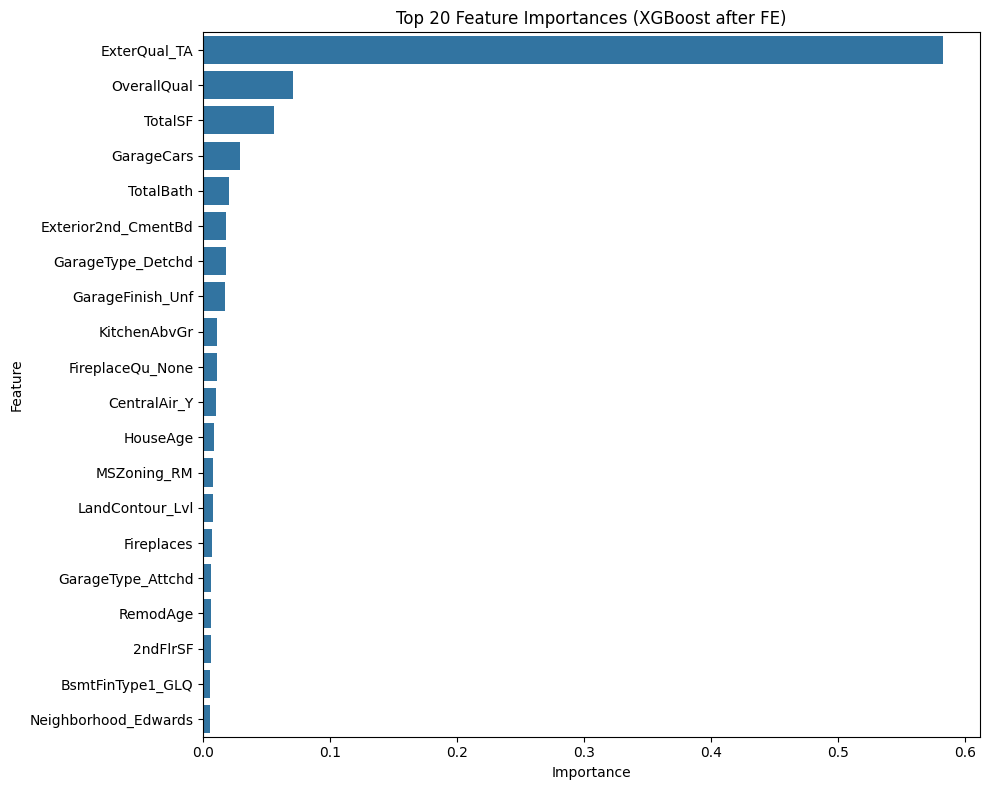

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_fe.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("=== Top 20 Most Important Features ===")
print(importance.head(20))

print("\n=== Bottom 15 Least Important Features ===")
print(importance.tail(15))

# Plot top 20
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance.head(20))
plt.title('Top 20 Feature Importances (XGBoost after FE)')
plt.tight_layout()
plt.show()

## 9.d. Clean Feature Selection + Retrain

In [21]:
# Keep only features with importance > 0
important_features = importance[importance['Importance'] > 0]['Feature'].tolist()

print(f"Number of features kept: {len(important_features)}")
print(f"Number of features dropped: {X_train.shape[1] - len(important_features)}")

# Create cleaned datasets
X_train_clean = X_train[important_features]
X_test_clean = X_test[important_features]

# Retrain XGBoost with the best parameters we found earlier
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

final_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.8,
    random_state=42
)

final_model.fit(X_train_clean, y_train)
y_pred_final = final_model.predict(X_test_clean)

print("\n=== Final Model after Feature Selection ===")
print("Test RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_final)))
print("Test R²   :", r2_score(y_test, y_pred_final))

Number of features kept: 139
Number of features dropped: 115

=== Final Model after Feature Selection ===
Test RMSE : 25624.26849687616
Test R²   : 0.9143970012664795


# 10. SUBMISSION

In [22]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor

# -------------------------------------------------
# 1. Load both datasets
# -------------------------------------------------
train = pd.read_csv('/kaggle/input/datasets/lyesaitk/house-train/train.csv')
test = pd.read_csv('/kaggle/input/datasets/lyesaitk/test-data/test.csv')

print("Train shape:", train.shape)
print("Test shape :", test.shape)

# -------------------------------------------------
# 2. Combine for consistent preprocessing
# -------------------------------------------------
train['is_train'] = 1
test['is_train'] = 0
test['SalePrice'] = np.nan          # temporary

full = pd.concat([train, test], axis=0, ignore_index=True)

# -------------------------------------------------
# 3. Handle Missing Values (same logic as before)
# -------------------------------------------------
# Drop high-missing columns
cols_to_drop = ['PoolQC', 'MiscFeature', 'Alley', 'Fence']
full.drop(columns=[col for col in cols_to_drop if col in full.columns], inplace=True)

# Fill categorical "None"
none_cols = ['MasVnrType', 'FireplaceQu', 'GarageType', 'GarageFinish',
             'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond',
             'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
for col in none_cols:
    if col in full.columns:
        full[col] = full[col].fillna('None')

# Numerical fills
full['LotFrontage'] = full['LotFrontage'].fillna(full['LotFrontage'].median())
full['GarageYrBlt'] = full['GarageYrBlt'].fillna(full['YearBuilt'])
full['MasVnrArea'] = full['MasVnrArea'].fillna(0)

if 'Electrical' in full.columns:
    full['Electrical'] = full['Electrical'].fillna(full['Electrical'].mode()[0])

# -------------------------------------------------
# 4. One-Hot Encoding
# -------------------------------------------------
categorical_cols = full.select_dtypes(include=['object']).columns.tolist()
full_encoded = pd.get_dummies(full, columns=categorical_cols, drop_first=True)

# -------------------------------------------------
# 5. Split back into train and test
# -------------------------------------------------
train_encoded = full_encoded[full_encoded['is_train'] == 1].copy()
test_encoded  = full_encoded[full_encoded['is_train'] == 0].copy()

# Remove helper columns
train_encoded.drop(columns=['is_train'], inplace=True)
test_encoded.drop(columns=['is_train', 'SalePrice'], inplace=True)

# Align columns (important!)
X = train_encoded.drop('SalePrice', axis=1)
y = train_encoded['SalePrice']

# Make sure test has exactly the same columns as X
test_encoded = test_encoded.reindex(columns=X.columns, fill_value=0)

print("\nFinal X shape:", X.shape)
print("Final test shape:", test_encoded.shape)

# -------------------------------------------------
# 6. Train the Best Model on FULL training data
# -------------------------------------------------
best_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.8,
    random_state=42
)

best_model.fit(X, y)
print("\nModel trained on full training data.")

# -------------------------------------------------
# 7. Predict and Create Submission
# -------------------------------------------------
predictions = best_model.predict(test_encoded)

# Create submission file
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': predictions
})

submission.to_csv('submission.csv', index=False)

print("\n✅ submission.csv created successfully!")
print(submission.head())
print(f"\nSubmission shape: {submission.shape}")

Train shape: (1460, 81)
Test shape : (1459, 80)

Final X shape: (1460, 247)
Final test shape: (1459, 247)

Model trained on full training data.

✅ submission.csv created successfully!
     Id      SalePrice
0  1461  124545.015625
1  1462  164002.984375
2  1463  178783.062500
3  1464  189792.421875
4  1465  185877.578125

Submission shape: (1459, 2)
